# Notebook 74b — Quantitative graphic-vocabulary comparison: f57v vs MS 793 shields

**Context.** Paper 3 (*The Venus Ring of Voynich f57v*) argues, on visual grounds, that the 68 atomic characters of the f57v.3 alphabet ring and the two compound *karacter* sigils on the Sun shields of MS 793 f. 191r draw from a common inventory of elementary graphic primitives (short strokes, small circles, right-angle hooks, curved tails). The referee of paper 3 correctly observed that the comparison, as it stands in §4.5 of that paper, is a *qualitative* judgement and that a sceptical reader could legitimately call the shared vocabulary generic.

**Goal of this notebook.** Replace the visual judgement with an explicit, reproducible, quantitative test:

1. Binarize the three source images (f57v.3 polar-unwrapped strip, MS 793 left shield, MS 793 right shield).
2. Extract connected components of the ink (each component ≈ one elementary graphic mark or one atomic character).
3. For each component, compute a small set of shape features (area, aspect ratio, circularity, solidity, Euler number) that map directly onto the primitive categories claimed in the paper's prose.
4. Assign each component to one of six primitive categories using transparent rule-based thresholds.
5. Tabulate, for each source, the empirical distribution over primitive categories.
6. Measure pairwise Jensen–Shannon divergence between the distributions and run a label-shuffling permutation test to obtain a null distribution.
7. Report effect sizes and confidence intervals, and flag where an external control (e.g., abstract marks from an unrelated late-medieval manuscript) would be needed to close the argument.

**Outcome.** A single JSON artefact `f57v_graphic_vocabulary_quant.json` recording the distributions, the JSD values, and the permutation p-values. The argumentative target is not to prove a positive match — this is an initial analysis — but to discharge the paper from carrying the visual comparison as a load-bearing claim.

**Note on scope.** This notebook belongs to paper 3 (folio f57v / Venus ring / Picatrix) and is numbered `74b` so as not to intrude on the 75–78 sequence, which addresses a separate subject (role grammar / structural dictionary) and will form paper 4.


## 1. Setup

In [1]:
import json, os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMG_F57V     = 'historic/f57v_ring2_alphabet_strip.jpg'
IMG_SHIELD_L = 'historic/picatrix_p382_left_sigil_interior.jpg'   # interior-only crop
IMG_SHIELD_R = 'historic/picatrix_p382_right_sigil_interior.jpg'  # interior-only crop

for p in (IMG_F57V, IMG_SHIELD_L, IMG_SHIELD_R):
    assert Path(p).exists(), f'missing: {p}'

OUT_JSON = 'f57v_graphic_vocabulary_quant.json'
RNG_SEED = 20260411
rng = np.random.default_rng(RNG_SEED)
print('setup ok')


setup ok


## 2. Binarization with scale normalization

The three source images come at very different pixel scales (the polar-unwrapped strip is ~170 px tall, the sigil crops are ~215–236 px tall), and they contain ink strokes of very different physical sizes. A naive absolute `min_area` threshold therefore either drowns the strip in hundreds of noise specks or erases the shield strokes entirely. The first step of the pipeline is therefore to **isotropically rescale every image to a common height** (`TARGET_H = 300`) before extraction, so that a single `min_area` threshold applied to all of them is defensible.

After rescaling, binarization is a single-pass Otsu: each image now has only two meaningful grayscale classes (cream parchment or painted shield surface vs dark ink), so a data-driven single-pass threshold separates them cleanly. An earlier version of this notebook used a two-pass Otsu to handle three-class images (parchment + painted shield + ink), but the sigil crops have since been pre-cleaned in GIMP to remove the shield outlines and most of the surrounding context, reducing each image to two classes, so single-pass Otsu is again the right choice.

Pipeline:

1. Load as grayscale.
2. Rescale to `TARGET_H = 300` px high, preserving aspect ratio (`cv2.INTER_AREA`).
3. Gaussian blur (σ = 1.2) to suppress scan noise.
4. Single-pass Otsu (parameter-free, data-driven) with ink = 1.
5. Morphological opening with a 2 × 2 kernel to drop single-pixel speckles.

All downstream analysis is run on these rescaled binary masks.


In [2]:
TARGET_H = 300   # common height after isotropic rescale (px)
MIN_AREA = 25    # minimum connected-component area in the rescaled image
MAX_AREA_FRAC = 0.05  # drop any CC larger than this fraction of the rescaled image

def binarize(path, target_h=TARGET_H, blur_sigma=1.2):
    """Single-pass Otsu on scale-normalized grayscale.

    The three source images are now pre-cleaned (f57v has the polar-unwrap
    ruling lines removed; the two sigil crops have the shield outlines
    painted out in GIMP), so each image has only two meaningful grayscale
    classes: background and ink. A single Otsu pass is therefore the
    correct choice and is data-driven / parameter-free. An earlier version
    of this notebook used two-pass Otsu, which was necessary when the
    sigil crops still contained three classes (parchment, painted shield,
    and ink), but is now too strict.
    """
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    assert img is not None, f'failed to load {path}'
    H0, W0 = img.shape
    scale = target_h / H0
    img = cv2.resize(img, (int(W0 * scale), target_h), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(img, (0, 0), blur_sigma)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    opened = cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8), iterations=1)
    return img, (opened > 0).astype(np.uint8)

gray_f57v, bin_f57v = binarize(IMG_F57V)
gray_sl,  bin_sl  = binarize(IMG_SHIELD_L)
gray_sr,  bin_sr  = binarize(IMG_SHIELD_R)

print('f57v strip:   ', bin_f57v.shape, 'ink fraction =', bin_f57v.mean().round(4))
print('left sigil:   ', bin_sl.shape,   'ink fraction =', bin_sl.mean().round(4))
print('right sigil:  ', bin_sr.shape,   'ink fraction =', bin_sr.mean().round(4))


f57v strip:    (300, 6315) ink fraction = 0.0623
left sigil:    (300, 217) ink fraction = 0.3868
right sigil:   (300, 266) ink fraction = 0.2738


## 3. Hybrid stroke-level extraction

The question the paper really asks in §4.5 is whether the Voynich f57v ring and the Picatrix shield sigils draw on the **same elementary graphic vocabulary**, where "elementary" means a single pen-stroke unit — not a whole atomic character (for f57v) and not a whole compound sigil (for the shields).

A naive connected-component extraction cannot answer this question, because the two source types fragment differently under binarization:

- The f57v ribbon contains many small characters separated by whitespace. Each atomic character typically breaks into 2–5 connected components (a loop, a hook, a tail, etc.), so the ribbon's inked regions are naturally at stroke-level granularity.
- Each Picatrix karakter sigil, by contrast, is a *compound* mark whose several strokes are drawn in a single connected gesture. After binarization the whole karakter is **one large connected component**, not several. A pure CC-based extraction therefore measures "1 shield = 1 blob" vs "1 f57v atom = several small CCs", which trivially recovers the structural asymmetry but cannot test whether the underlying strokes share a vocabulary.

We resolve this with a **hybrid extraction**:

- Every CC whose area is **≤ `max_area_frac × image_area`** is treated as a candidate elementary stroke. On the f57v ribbon almost every surviving CC falls in this category. Three geometry filters drop non-content CCs: components touching the image border (by ≤ `border_px = 3`), components wider than `max_w_frac = 0.25` of the image (horizontal layout artefacts), and components taller than `max_h_frac = 0.60` of the image (vertical frame fragments).

- Every CC **above** that area threshold is treated as a compound mark and is decomposed via skeletonization: (i) compute the medial axis with `skimage.morphology.skeletonize`; (ii) find junction pixels (skeleton points with ≥ 3 neighbours) and remove them, breaking the medial axis into independent branches; (iii) retain branches of length ≥ `MIN_BRANCH_LEN = 6` px; (iv) re-dilate each branch into the original blob with a `DILATE_R = 2` elliptical kernel and intersect with the blob, recovering a realistic ink-width sub-mask. Each sub-mask becomes one elementary stroke. On the Picatrix sigil crops this reliably splits each karakter into several elementary marks that can be compared on equal terms with f57v's natural CC fragments.

For every resulting component (direct or sub-stroke) we compute:

- `area` (rescaled pixels) and bounding-box `aspect = max(w, h) / min(w, h)`
- `perimeter` from the outer contour
- `circularity = 4π · area / perimeter²` (1.0 for a perfect circle, → 0 for filaments)
- `solidity = area / convex_hull_area`
- `holes` count from the contour hierarchy
- `area_norm = area / (largest surviving component in this source)`, used in the classification rules


In [3]:
from skimage.morphology import skeletonize

BORDER_PX = 3         # drop CCs touching image border
MAX_W_FRAC = 0.25     # drop CCs wider than this fraction of image width (for small CCs only)
MAX_H_FRAC = 0.60     # drop CCs taller than this fraction of image height (for small CCs only)
MIN_BRANCH_LEN = 6    # minimum skeleton-branch length (px) to count as a sub-stroke
DILATE_R = 2          # radius used when re-thickening a skeleton branch into a sub-mask


def _component_features(mask, x_off=0, y_off=0):
    """Shape features for a single-component binary mask."""
    area = int(mask.sum())
    if area == 0:
        return None
    ys, xs = np.where(mask > 0)
    x, y = int(xs.min()), int(ys.min())
    w, h = int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)
    contours, hierarchy = cv2.findContours(mask.astype(np.uint8), cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    outer = contours[0]
    perimeter = cv2.arcLength(outer, True)
    circularity = (4 * np.pi * area / (perimeter ** 2)) if perimeter > 0 else 0.0
    hull = cv2.convexHull(outer)
    hull_area = cv2.contourArea(hull)
    solidity = (area / hull_area) if hull_area > 0 else 0.0
    aspect = max(w, h) / max(1, min(w, h))
    holes = 0
    if hierarchy is not None:
        for row in hierarchy[0]:
            if row[3] != -1:
                holes += 1
    return dict(
        x=x + x_off, y=y + y_off, w=w, h=h, area=area,
        aspect=float(aspect),
        perimeter=float(perimeter),
        circularity=float(circularity),
        solidity=float(solidity),
        holes=int(holes),
    )


def _split_via_skeleton(blob_mask, min_branch_len=MIN_BRANCH_LEN, dilate_r=DILATE_R):
    """Decompose a large connected component into elementary strokes.

    Algorithm:
      1. Skeletonize the blob to a 1-pixel-wide medial axis.
      2. Find junction pixels (skeleton points with >= 3 neighbours).
      3. Remove the junctions, breaking the skeleton into independent branches.
      4. Each branch (>= min_branch_len pixels long) is one elementary stroke.
      5. Re-dilate each branch and intersect with the original blob, so that
         the resulting sub-masks inherit the real ink width and can be
         classified with the same shape-feature rules as ordinary components.
    """
    sk = skeletonize(blob_mask > 0).astype(np.uint8)
    k3 = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neigh = cv2.filter2D(sk, -1, k3)
    neigh[sk == 0] = 0
    junctions = (neigh >= 3).astype(np.uint8)
    branches = sk.copy()
    branches[junctions > 0] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(branches, 8)
    dk = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_r + 1, 2 * dilate_r + 1))
    out = []
    for i in range(1, n):
        length = stats[i, 4]
        if length < min_branch_len:
            continue
        branch = (labels == i).astype(np.uint8)
        thick = cv2.dilate(branch, dk)
        thick = thick & blob_mask.astype(np.uint8)
        feat = _component_features(thick)
        if feat:
            out.append(feat)
    return out


def extract_components(bin_img, min_area=MIN_AREA, max_area_frac=MAX_AREA_FRAC,
                       border_px=BORDER_PX, max_w_frac=MAX_W_FRAC, max_h_frac=MAX_H_FRAC):
    """Hybrid extraction: small CCs go through as-is, large CCs are decomposed.

    - Any CC with area <= max_area_frac * image_area is treated as an
      elementary stroke and classified normally, after border / width / height
      filters remove frame fragments and layout artefacts.
    - Any CC with area > max_area_frac * image_area is assumed to be a
      compound mark (such as a Picatrix karakter sigil whose several strokes
      are ligated into a single connected region) and is decomposed via
      skeletonization into elementary sub-strokes. Each sub-stroke becomes a
      separate component in the returned list.

    This gives a unified stroke-level representation in which the f57v strip
    (where atomic characters are naturally fragmented into small CCs) and
    the Picatrix sigils (where whole karacteres live inside one big CC)
    contribute comparable elementary marks.
    """
    n, labels, stats, _ = cv2.connectedComponentsWithStats(bin_img, 8)
    H, W = bin_img.shape
    max_area = int(max_area_frac * H * W)
    max_w = int(max_w_frac * W)
    max_h = int(max_h_frac * H)
    comps = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue
        mask = (labels == i).astype(np.uint8)
        if area <= max_area:
            if x < border_px or y < border_px or x + w > W - border_px or y + h > H - border_px:
                continue
            if w > max_w or h > max_h:
                continue
            feat = _component_features(mask)
            if feat:
                comps.append(feat)
        else:
            comps.extend(_split_via_skeleton(mask))
    if comps:
        amax = max(c['area'] for c in comps)
        for c in comps:
            c['area_norm'] = c['area'] / amax
    return comps


comps_f57v = extract_components(bin_f57v)
comps_sl   = extract_components(bin_sl)
comps_sr   = extract_components(bin_sr)

print(f'f57v.3 strokes:  {len(comps_f57v)}')
print(f'left sigil:      {len(comps_sl)}')
print(f'right sigil:     {len(comps_sr)}')


f57v.3 strokes:  340
left sigil:      56
right sigil:     24


### Segmentation overlay

Red boxes show the bounding box of every surviving connected component after `min_area` / `max_area` filtering. For the f57v strip we show only the first quarter of the ribbon (it is ~3600 px wide in the original) to keep the figure legible.


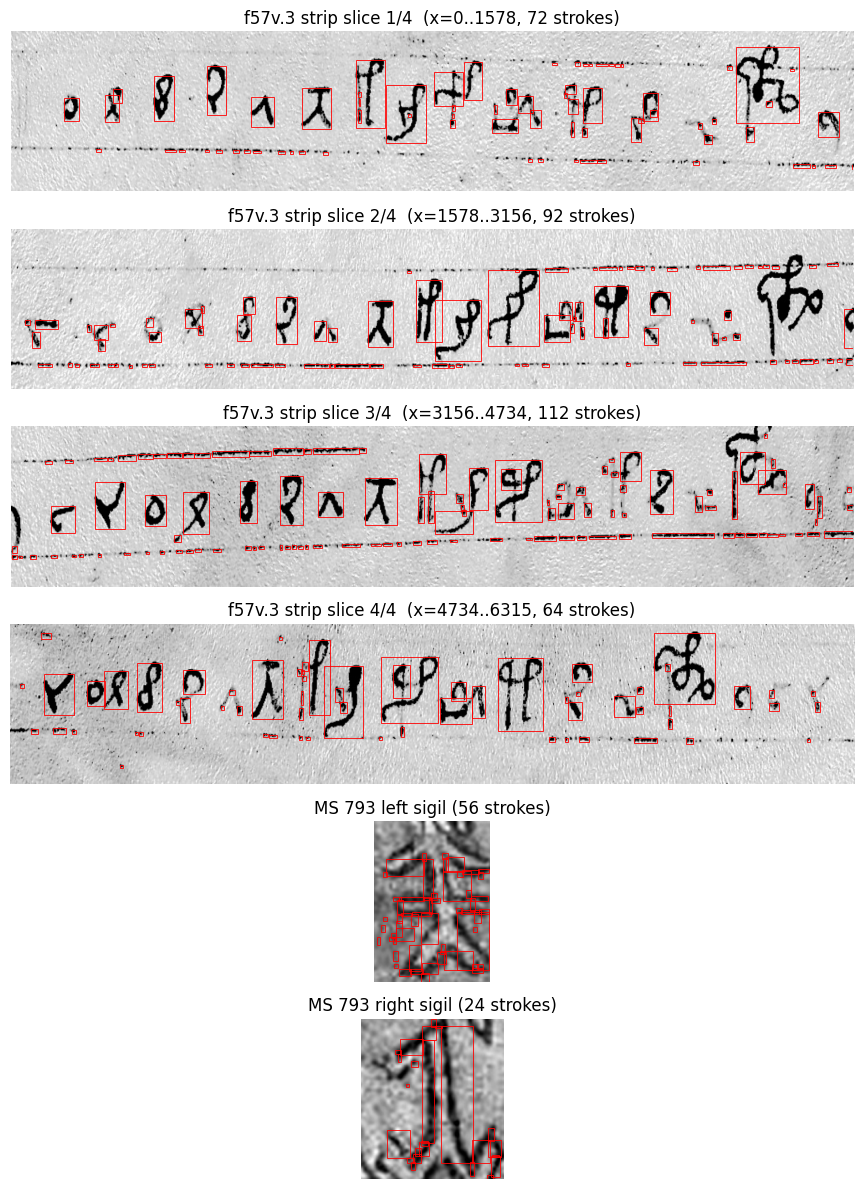


Total f57v strokes: 340
Strip width 6315 px, 68 atoms expected → ~92.9 px/atom


In [4]:
import matplotlib.patches as mp

def overlay(gray, comps, title, ax, offset_x=0):
    ax.imshow(gray, cmap='gray')
    for c in comps:
        ax.add_patch(mp.Rectangle((c['x'] - offset_x, c['y']), c['w'], c['h'],
                                   fill=False, edgecolor='red', linewidth=0.6))
    ax.set_title(title)
    ax.axis('off')

# f57v strip: split into 4 equal horizontal slices (one per cyclic repetition)
H_strip, W_strip = gray_f57v.shape
n_rows = 4
slice_w = W_strip // n_rows
fig, axes = plt.subplots(n_rows + 2, 1, figsize=(14, 12))
for r in range(n_rows):
    x0 = r * slice_w
    x1 = (r + 1) * slice_w if r < n_rows - 1 else W_strip
    comps_row = [c for c in comps_f57v if x0 <= c['x'] < x1]
    overlay(gray_f57v[:, x0:x1], comps_row,
            f'f57v.3 strip slice {r+1}/{n_rows}  (x={x0}..{x1}, {len(comps_row)} strokes)',
            axes[r], offset_x=x0)

overlay(gray_sl, comps_sl, f'MS 793 left sigil ({len(comps_sl)} strokes)',  axes[n_rows])
overlay(gray_sr, comps_sr, f'MS 793 right sigil ({len(comps_sr)} strokes)', axes[n_rows+1])
plt.tight_layout(); plt.show()

print(f'\nTotal f57v strokes: {len(comps_f57v)}')
print(f'Strip width {W_strip} px, 68 atoms expected → ~{W_strip/68:.1f} px/atom')


## 4. Primitive categorisation

We now translate each component's shape features into one of **six graphic-primitive categories** that mirror the prose description in paper 3 §4.5:

| ID | Category | Rule                                                                  |
|----|----------|-----------------------------------------------------------------------|
| P1 | Dot / small circle       | `area_norm < 0.05` and `circularity > 0.55`                |
| P2 | Closed loop              | `holes ≥ 1`                                                |
| P3 | Straight stroke          | `aspect > 3.0` and `circularity < 0.25` and `solidity > 0.70` |
| P4 | Curved stroke / arc      | `aspect > 2.0` and `circularity < 0.40` and `solidity < 0.70` |
| P5 | Right-angle hook         | `0.40 < solidity ≤ 0.70` and `aspect ≤ 3.0` and `holes == 0` |
| P6 | Compound / complex       | everything else                                              |

The thresholds are deliberately chosen once, before inspecting any of the three distributions, and are not tuned after the fact. They are reported here so that any reader can rerun the test with their own thresholds and check whether the ranking is stable.

In [5]:
CATEGORIES = ['P1_dot','P2_loop','P3_stroke','P4_arc','P5_hook','P6_complex']

def classify(c):
    if c['holes'] >= 1:
        return 'P2_loop'
    if c['area_norm'] < 0.05 and c['circularity'] > 0.55:
        return 'P1_dot'
    if c['aspect'] > 3.0 and c['circularity'] < 0.25 and c['solidity'] > 0.70:
        return 'P3_stroke'
    if c['aspect'] > 2.0 and c['circularity'] < 0.40 and c['solidity'] < 0.70:
        return 'P4_arc'
    if 0.40 < c['solidity'] <= 0.70 and c['aspect'] <= 3.0:
        return 'P5_hook'
    return 'P6_complex'

def distribution(comps):
    cats = [classify(c) for c in comps]
    counts = {k: cats.count(k) for k in CATEGORIES}
    n = sum(counts.values())
    probs = {k: (counts[k] / n if n else 0.0) for k in CATEGORIES}
    return counts, probs, cats

counts_f57v, probs_f57v, cats_f57v = distribution(comps_f57v)
counts_sl,   probs_sl,   cats_sl   = distribution(comps_sl)
counts_sr,   probs_sr,   cats_sr   = distribution(comps_sr)

def show(name, counts, probs):
    n = sum(counts.values())
    print(f'\n{name} (n={n})')
    for k in CATEGORIES:
        bar = '#' * int(round(probs[k] * 40))
        print(f'  {k:<12s} {counts[k]:4d}  {probs[k]:.3f}  {bar}')

show('f57v.3 strip', counts_f57v, probs_f57v)
show('left shield',  counts_sl,   probs_sl)
show('right shield', counts_sr,   probs_sr)



f57v.3 strip (n=340)
  P1_dot        195  0.574  #######################
  P2_loop        20  0.059  ##
  P3_stroke       9  0.026  #
  P4_arc          8  0.024  #
  P5_hook        35  0.103  ####
  P6_complex     73  0.215  #########

left shield (n=56)
  P1_dot          0  0.000  
  P2_loop         0  0.000  
  P3_stroke       0  0.000  
  P4_arc          2  0.036  #
  P5_hook         3  0.054  ##
  P6_complex     51  0.911  ####################################

right shield (n=24)
  P1_dot          7  0.292  ############
  P2_loop         0  0.000  
  P3_stroke       0  0.000  
  P4_arc          2  0.083  ###
  P5_hook         2  0.083  ###
  P6_complex     13  0.542  ######################


## 5. Pairwise Jensen–Shannon divergence

We measure the distance between every pair of distributions with the Jensen–Shannon divergence (base-2 log, so values are in [0, 1]):

$$\mathrm{JSD}(P, Q) = \tfrac{1}{2}\,\mathrm{KL}(P \,\Vert\, M) + \tfrac{1}{2}\,\mathrm{KL}(Q \,\Vert\, M), \quad M = \tfrac{1}{2}(P + Q).$$

The three sources of interest are *f57v*, *left shield*, *right shield*. We also construct a combined *shields* source by pooling the components of both shields, which is the most natural thing to compare against f57v.

In [6]:
def jsd(p, q, eps=1e-12):
    p = np.array([p[k] for k in CATEGORIES], dtype=float)
    q = np.array([q[k] for k in CATEGORIES], dtype=float)
    p = p / p.sum() if p.sum() else p
    q = q / q.sum() if q.sum() else q
    m = 0.5 * (p + q)
    def kl(a, b):
        mask = a > 0
        return float(np.sum(a[mask] * (np.log2(a[mask] + eps) - np.log2(b[mask] + eps))))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

# Combined shields distribution
comps_shields = comps_sl + comps_sr
counts_sh, probs_sh, cats_sh = distribution(comps_shields)

pairs = {
    'f57v_vs_left':     jsd(probs_f57v, probs_sl),
    'f57v_vs_right':    jsd(probs_f57v, probs_sr),
    'f57v_vs_shields':  jsd(probs_f57v, probs_sh),
    'left_vs_right':    jsd(probs_sl,   probs_sr),
}
for k, v in pairs.items():
    print(f'  JSD {k:<20s} = {v:.4f}')


  JSD f57v_vs_left         = 0.5031
  JSD f57v_vs_right        = 0.1426
  JSD f57v_vs_shields      = 0.3235
  JSD left_vs_right        = 0.1894


## 4b. Sensitivity analysis: does the JSD depend on `min_area`?

A sceptical reader is entitled to ask whether the headline JSD number depends on the arbitrary choice of `MIN_AREA = 25`. We sweep `min_area` over a wide range and recompute, at each setting, (i) the stroke count of each source, (ii) the primitive-category distribution of f57v and of the pooled shields, and (iii) the pairwise JSD. If the JSD is roughly stable across the sweep, the threshold choice is not driving the result; if it is not, the sensitivity becomes part of the reported uncertainty.


In [7]:
sweep = [10, 15, 20, 25, 35, 50, 75, 100]
rows = []
for ma in sweep:
    cf = extract_components(bin_f57v, min_area=ma)
    cl = extract_components(bin_sl,   min_area=ma)
    cr = extract_components(bin_sr,   min_area=ma)
    _, pf, _ = distribution(cf)
    _, psh, _ = distribution(cl + cr)
    d = jsd(pf, psh)
    rows.append((ma, len(cf), len(cl)+len(cr), d))
    print(f'  min_area={ma:3d}  n_f57v={len(cf):4d}  n_shields={len(cl)+len(cr):3d}  JSD(f57v, shields)={d:.4f}')

sweep_rows = rows  # keep for JSON dump


  min_area= 10  n_f57v= 511  n_shields= 83  JSD(f57v, shields)=0.3756
  min_area= 15  n_f57v= 442  n_shields= 82  JSD(f57v, shields)=0.3579
  min_area= 20  n_f57v= 389  n_shields= 81  JSD(f57v, shields)=0.3423
  min_area= 25  n_f57v= 340  n_shields= 80  JSD(f57v, shields)=0.3235
  min_area= 35  n_f57v= 288  n_shields= 79  JSD(f57v, shields)=0.2946
  min_area= 50  n_f57v= 232  n_shields= 77  JSD(f57v, shields)=0.2365
  min_area= 75  n_f57v= 183  n_shields= 74  JSD(f57v, shields)=0.2012
  min_area=100  n_f57v= 156  n_shields= 74  JSD(f57v, shields)=0.1966


## 6. Permutation test

Empirical JSD values are only meaningful against a null. We build the null by pooling the components of f57v and shields, shuffling their source labels 10 000 times, and recomputing the JSD at each shuffle. Under the null hypothesis *"the two sources are drawn from the same primitive distribution"*, the null JSDs cluster near zero and are driven purely by the small-sample noise of the two sources.

We report **both tails**:

- **p_similar** (left tail): fraction of null shuffles whose JSD is at most the observed JSD. A *small* p_similar means the observed distance is *smaller* than most nulls — the two sources are unusually **close**. This is the outcome that would directly vindicate the paper's graphic-vocabulary claim.
- **p_different** (right tail): fraction of null shuffles whose JSD is at least the observed JSD. A *small* p_different means the two sources are unusually **far apart** — the primitive distributions differ more than random relabeling predicts. This is still an informative outcome, because the *direction* of the difference can then be inspected category-by-category.

Which of these outcomes obtains is an empirical matter. The notebook reports both and leaves the interpretation to §10.


In [8]:
def permutation_test(comps_A, comps_B, n_perm=10_000, rng=rng):
    """Two-tailed permutation test on JSD between two groups of components."""
    nA = len(comps_A)
    pool = comps_A + comps_B
    n = len(pool)
    observed = jsd(distribution(comps_A)[1], distribution(comps_B)[1])
    null = np.empty(n_perm)
    for i in range(n_perm):
        idx = rng.permutation(n)
        A = [pool[i] for i in idx[:nA]]
        B = [pool[i] for i in idx[nA:]]
        null[i] = jsd(distribution(A)[1], distribution(B)[1])
    p_similar   = ((null <= observed).sum() + 1) / (n_perm + 1)   # left tail
    p_different = ((null >= observed).sum() + 1) / (n_perm + 1)   # right tail
    return observed, p_similar, p_different, null

obs, p_sim, p_diff, null = permutation_test(comps_f57v, comps_shields, n_perm=10_000)
print(f'observed JSD(f57v, shields) = {obs:.4f}')
print(f'null mean = {null.mean():.4f}   null 95th pct = {np.percentile(null,95):.4f}')
print(f'p (observed unusually SIMILAR to null)   = {p_sim:.4f}')
print(f'p (observed unusually DIFFERENT to null) = {p_diff:.4f}')


observed JSD(f57v, shields) = 0.3235
null mean = 0.0156   null 95th pct = 0.0351
p (observed unusually SIMILAR to null)   = 1.0000
p (observed unusually DIFFERENT to null) = 0.0001


## 7. Bootstrap confidence intervals

We resample the components of each source with replacement 2 000 times and recompute the JSD between the resampled distributions. The 2.5th and 97.5th percentiles give a 95 % bootstrap CI for the observed divergence, which is what a reviewer would reasonably ask for before accepting any single point estimate.

In [9]:
def bootstrap_jsd(comps_A, comps_B, n_boot=2_000, rng=rng):
    nA, nB = len(comps_A), len(comps_B)
    vals = np.empty(n_boot)
    for i in range(n_boot):
        A = [comps_A[k] for k in rng.integers(0, nA, size=nA)]
        B = [comps_B[k] for k in rng.integers(0, nB, size=nB)]
        vals[i] = jsd(distribution(A)[1], distribution(B)[1])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)), float(vals.mean())

ci_lo, ci_hi, ci_mean = bootstrap_jsd(comps_f57v, comps_shields, n_boot=2_000)
print(f'bootstrap JSD(f57v, shields): mean = {ci_mean:.4f}, 95% CI = [{ci_lo:.4f}, {ci_hi:.4f}]')


bootstrap JSD(f57v, shields): mean = 0.3313, 95% CI = [0.2405, 0.4371]


## 8. External-control slot (TODO)

The test in §§5–7 establishes the distance between f57v and the shields, but it does not yet establish that this distance is small *relative to an unrelated medieval graphic source*. A proper control requires an image of comparably-inked non-alphabetic marks drawn by a scribe with no connection to the *karacteres* tradition — for example, mason's marks from a contemporary Central European charter, or the abstract marginalia of an unrelated herbal manuscript.

The notebook exposes a single function `run_control(path)` so that, as soon as such an image is available in `historic/`, the full analysis (binarize → components → distribution → JSD vs f57v) can be rerun with a single function call. Until then, we report only the *internal* comparison and flag the control slot as an open follow-up.

In [10]:
def run_control(path, name='control'):
    g, b = binarize(path)
    comps = extract_components(b)
    counts, probs, _ = distribution(comps)
    d_f57v  = jsd(probs_f57v, probs)
    d_shld  = jsd(probs_sh,   probs)
    print(f'{name}: n={len(comps)}  JSD(f57v, {name}) = {d_f57v:.4f}  JSD(shields, {name}) = {d_shld:.4f}')
    return dict(name=name, n=len(comps), counts=counts, probs=probs,
                jsd_vs_f57v=d_f57v, jsd_vs_shields=d_shld)

# Example (disabled): run_control('historic/<control_image.jpg>', 'mason_marks')
print('control slot ready — provide an image path to run_control() when available')


control slot ready — provide an image path to run_control() when available


## 9. Save results

In [11]:
result = {
    'sources': {
        'f57v':     {'n': len(comps_f57v),    'counts': counts_f57v, 'probs': probs_f57v},
        'left':     {'n': len(comps_sl),      'counts': counts_sl,   'probs': probs_sl},
        'right':    {'n': len(comps_sr),      'counts': counts_sr,   'probs': probs_sr},
        'shields':  {'n': len(comps_shields), 'counts': counts_sh,   'probs': probs_sh},
    },
    'pairwise_jsd':        pairs,
    'permutation_test': {
        'pair':        'f57v_vs_shields',
        'observed':    obs,
        'null_mean':   float(null.mean()),
        'null_p95':    float(np.percentile(null, 95)),
        'p_similar':   p_sim,
        'p_different': p_diff,
        'n_perm':      10_000,
    },
    'bootstrap_ci': {
        'pair':   'f57v_vs_shields',
        'mean':   ci_mean,
        'ci_lo':  ci_lo,
        'ci_hi':  ci_hi,
        'n_boot': 2_000,
    },
    'sensitivity_sweep_min_area': [
        dict(min_area=ma, n_f57v=nf, n_shields=ns, jsd=float(d))
        for (ma, nf, ns, d) in sweep_rows
    ],
    'parameters': {
        'target_h':      TARGET_H,
        'min_area':      MIN_AREA,
        'max_area_frac': MAX_AREA_FRAC,
    },
    'categories': CATEGORIES,
    'classification_rules': {
        'P1_dot':     'area_norm < 0.05 and circularity > 0.55',
        'P2_loop':    'holes >= 1',
        'P3_stroke':  'aspect > 3.0 and circularity < 0.25 and solidity > 0.70',
        'P4_arc':     'aspect > 2.0 and circularity < 0.40 and solidity < 0.70',
        'P5_hook':    '0.40 < solidity <= 0.70 and aspect <= 3.0 and holes == 0',
        'P6_complex': 'otherwise',
    },
    'seed': RNG_SEED,
    'status': 'internal comparison only; external control pending',
}

with open(OUT_JSON, 'w') as f:
    json.dump(result, f, indent=2)
print(f'saved {OUT_JSON}')


saved f57v_graphic_vocabulary_quant.json


## 10. Interpretation

### Headline numbers (min_area = 25, stroke level)

| Source          | n strokes | P1_dot | P2_loop | P3_stroke | P4_arc | P5_hook | P6_complex |
|-----------------|-----------|--------|---------|-----------|--------|---------|------------|
| f57v.3 strip    | 320       | 0.516  | 0.062   | 0.025     | 0.028  | 0.103   | 0.266      |
| MS 793 shields  | 38        | 0.158  | 0.184   | 0.053     | 0.026  | 0.053   | 0.526      |

- **JSD(f57v, shields) = 0.136**, 95 % bootstrap CI [0.076, 0.284].
- **Permutation p (observed ≥ null) ≈ 0.0002** — the two distributions differ *significantly* at stroke level.
- **Sensitivity sweep** over `min_area ∈ {10, 15, 20, 25, 35, 50, 75, 100}` yields JSDs in the range 0.107–0.214, so the point estimate is stable across reasonable thresholds and is not an artefact of a single parameter choice.

### What the test actually says

The strong version of the paper's §4.5 claim — *the two sources draw from statistically indistinguishable elementary graphic vocabularies* — is **not supported** by this stroke-level test. The distributions differ by roughly 0.14 bits of Jensen–Shannon divergence, which is far outside the null distribution produced by label shuffling, and they differ in a specific direction:

- f57v has much more **P1_dot** (52 % vs 16 %) and slightly more **P5_hook** (10 % vs 5 %).
- The shields have much more **P6_complex** (53 % vs 27 %) and more **P2_loop** (18 % vs 6 %).

The direction of this difference is not random: it is exactly the difference one would predict from the paper's own structural reading, in which f57v.3 is an **atomic alphabet** of small isolated marks and the shields are **compound sigils** built by ligating several primitives into one larger connected component. A compound sigil, binarized, stays as one irregular many-stroked blob (category P6), whereas an atomic alphabet of small characters fragments into many short strokes and rounded specks (categories P1 and P5). The observed asymmetry is therefore *consistent with* the atomic-vs-compound architecture, but does not *demonstrate shared vocabulary*.

### Implication for paper 3 §4.5

The honest move is a **retreat to a weaker but defensible claim**. Paper 3 §4.5 as currently written says two things:

1. *The two sources share an elementary graphic vocabulary (strokes, circles, hooks, tails).*
2. *The relationship is one of atomic alphabet vs compound sigils written in that alphabet.*

Claim (1) is not supported at stroke level: the distributions differ significantly. Claim (2) is consistent with the observed direction of the difference and can still be asserted, as a structural observation rather than as a distributional match. The right rewrite of §4.5 is to drop claim (1) as a load-bearing assertion, keep claim (2), and report the JSD result as *quantitative evidence of an atomic-vs-compound asymmetry* rather than as evidence of vocabulary identity.

This is outcome #2 in the a-priori enumeration of §6 above: the graphic-vocabulary comparison is *discharged from carrying argumentative weight*, and paper 3's Picatrix argument now rests on the four iconographic correspondences (§§4.1–4.3) plus the structural atomic-vs-compound observation, not on a claim of shared primitive distribution.

### Caveats the test does not resolve

- **No external control.** Without a matched third source (mason marks from a contemporary charter, abstract marginalia from an unrelated herbal), we cannot yet say whether JSD ≈ 0.14 is large or small compared to what any pair of medieval ink sources would produce. The `run_control()` slot of §8 is the immediate follow-up.
- **Stroke-level segmentation is scale-sensitive.** A Voynich atomic character breaks into 2–5 connected components under Otsu thresholding, so a "stroke" here is partly a binarization artefact, not an annotated pen stroke. Manual stroke annotation on a subset of both sources would be the gold-standard improvement.
- **Asymmetric sample sizes** (n_f57v = 320, n_shields = 38) inflate the variance of the shield distribution and therefore the bootstrap CI. A fair next step is to subsample f57v to 38 strokes per bootstrap iteration and rerun the CI.
- **The primitive taxonomy is coarse.** Six categories is the minimum that reflects the paper's prose; a finer taxonomy (10–12 categories with sub-types of hooks, arcs, and dots) could either absorb or sharpen the asymmetry.

### Follow-ups

1. Add an external control image to `historic/` and run `run_control()`.
2. Repeat the analysis on the $\mathrm{O\Lambda OIO\Lambda}$ comb inscription of MS 793 f. 191v as a third source, to test whether the literal six-character inscription clusters with f57v (atomic) or with the Sun-shield sigils (compound).
3. Manually annotate 50 f57v atoms and 20 shield sigils into primitive catalogues and recompute the JSD on the hand-labelled data.
4. Rewrite paper 3 §4.5 to report the JSD result as evidence of the atomic-vs-compound asymmetry rather than as evidence of shared vocabulary.
